In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from statsmodels.tsa.seasonal import seasonal_decompose

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D

In [2]:
df_raw = pd.read_hdf('data/3200CR001_26-3-2024.h5')

In [3]:
df = df_raw.copy()
df.drop_duplicates(subset='tiempo', inplace=True)
df.loc[:, df.select_dtypes('number').columns] = df.select_dtypes('number').interpolate(method='linear')
df.set_index('tiempo', inplace=True)

In [4]:
df_aggregation = df.select_dtypes('number').apply(lambda variable: variable.resample('h').mean())
df_aggregation.fillna(0, inplace=True)

In [42]:
# df_derivative = df_aggregation.apply(lambda variable: variable.diff())
# df_derivative.dropna(inplace=True)

In [5]:
df_trend = df_aggregation.apply(lambda variable: seasonal_decompose(variable, model = 'additive', extrapolate_trend='freq').trend)
#df_derivative_trend = df_derivative.apply(lambda variable: seasonal_decompose(variable, model = 'additive', extrapolate_trend='freq').trend)

In [7]:
variable = df_trend.columns[5]
linePlot(data = df_trend, x=df_trend.index, y=variable, color=None)

In [5]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df_split      = preData.splitTimeSeries()
# dfRaw = preData.crusher1Raw

# scaler  = StandardScaler()
# preData.normalizeData(scaler);

In [42]:
from statsmodels.tsa.seasonal import seasonal_decompose
def decompose(df, column_name):
    """
    A function that returns the trend, seasonality and residual captured by applying both multiplicative and
    additive model.
    df -> DataFrame
    column_name -> column_name for which trend, seasonality is to be captured
    """
    #result_mul = seasonal_decompose(df[column_name].resample('h').mean(), model='multiplicative') #, extrapolate_trend = 'freq')
    result_add = seasonal_decompose(df[column_name], model = 'additive') #, extrapolate_trend='freq')

    plt.rcParams.update({'figure.figsize': (20, 10)})
    #result_mul.plot()#.suptitle('Multiplicative Decompose', fontsize=30)
    result_add.plot() #.suptitle('Additive Decompose', fontsize=30)
    plt.show()
    
    #return result_mul, result_add
    return result_add

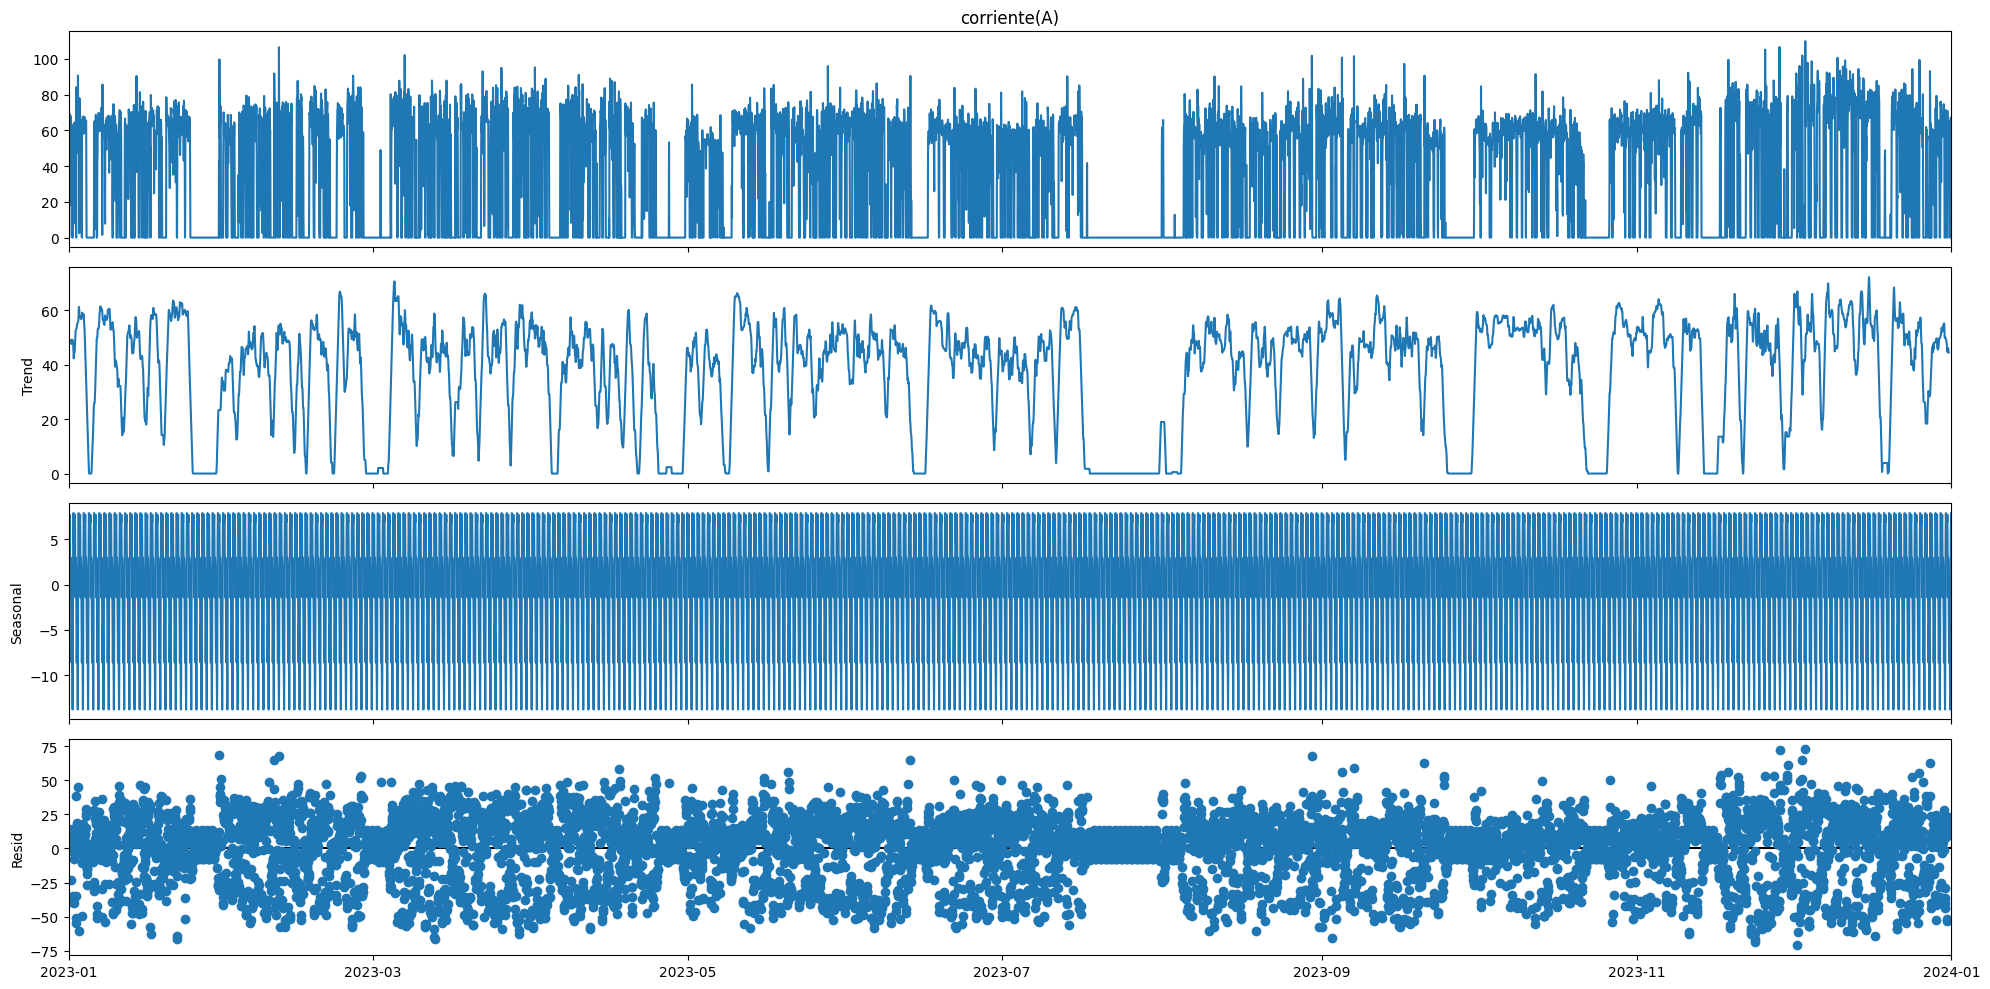

In [44]:
variable = df_aggregation.columns[0]
result_add = decompose(df_aggregation, variable)